# 第 8 章配套 Notebook：带符号、多阈值和差分编码（DCGS 逐公式验证）

[![Open In Colab (main)](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/main/notion/notebooks/ch08_signed_multithreshold_diff.ipynb) （PR 审查期分支链接：[点此在 Colab 打开 gemini/deep-03 版](https://colab.research.google.com/github/Casey-sketch-cyber/gnn2gsnn/blob/gemini/deep-03/notion/notebooks/ch08_signed_multithreshold_diff.ipynb)）

> **运行环境**：仅需 Python ≥ 3.10、`numpy`、`matplotlib`，不需要 GPU，也不依赖 PyTorch 等深度学习框架。所有公式推导、手算例与反例均直接打印中间结果并与第 8 章正文逐位核对一致。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# 配置中文与负号显示（Windows / Linux / macOS / Colab 通用回退）
matplotlib.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'Arial Unicode MS', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
np.set_printoptions(precision=6, suppress=True)
print("NumPy version:", np.__version__)


NumPy version: 2.5.5


## 1. 带符号脉冲神经元（Signed IF）：撤回“冤枉脉冲”与表达负值（例 8.1）

在第 7 章里我们看到，普通单极性 IF 神经元只能发 `0` 或 `+1`：
- **问题 A（无法纠偏）**：若前期先收到正电流误发了一个 `+1`，后期再收到负电流把膜电位拉成负数，单极性 IF 无法发 `-1` 把误发脉冲撤回来（到达不均匀误差）；
- **问题 B（无法表达负激活）**：如 ViG 的相对特征差 $\tilde{\mathbf{x}}_j - \tilde{\mathbf{x}}_i$ 或 GELU 的负半轴输出本身为负，单极性 IF 只能截为 `0`。

下面复现**例 8.1**：
1. **例 8.1A（撤回冤枉脉冲）**：$T=4, \theta=1.0, v[0]=0$，波动电流 $z[1..4] = [+1.5, -1.5, 0.0, 0.0]$，均值 $\bar{z}=0.0$、$\mathrm{ReLU}(\bar{z})=0.0$。对比普通 IF 与带符号 IF（ReLU 守卫模式：仅当已累计发过正脉冲 $S_{\mathrm{acc}}>0$ 且 $v^-[t] \le -\theta$ 时发 `-1`）；
2. **例 8.1B（表达负实数）**：无守卫恒等带符号 IF（对应 DCGS 的 $n=1$ 恒等神经元）在恒定负输入 $z = -0.50$、$T=4$ 下，发出 `[0, -1, 0, -1]`，平均率精准还原 `-0.50`。

In [2]:
def run_unipolar_if(z_seq, theta=1.0, v0=0.0, eps=1e-9):
    v = float(v0)
    rows = []
    for t, z in enumerate(z_seq, 1):
        v_pre = v + z
        s = 1.0 if v_pre >= theta - eps else 0.0
        v = v_pre - theta * s
        rows.append((t, z, v_pre, s, v))
    r = sum(row[3] for row in rows) / len(z_seq)
    return rows, r

def run_signed_if(z_seq, theta=1.0, v0=0.0, relu_guard=True, eps=1e-9):
    v = float(v0)
    s_acc = 0.0
    rows = []
    for t, z in enumerate(z_seq, 1):
        v_pre = v + z
        if v_pre >= theta - eps:
            s = 1.0
        elif v_pre <= -theta + eps and ((not relu_guard) or s_acc > 0):
            s = -1.0
        else:
            s = 0.0
        s_acc += s
        v = v_pre - theta * s
        rows.append((t, z, v_pre, s, v, s_acc))
    r = sum(row[3] for row in rows) / len(z_seq)
    return rows, r

# 例 8.1A: 撤回前期误发正脉冲
z_seq_A = [1.5, -1.5, 0.0, 0.0]
rows_uni, r_uni = run_unipolar_if(z_seq_A)
rows_sgn, r_sgn = run_signed_if(z_seq_A, relu_guard=True)

print("=== 例 8.1A: z = [+1.5, -1.5, 0, 0], true ReLU(mean z) = 0.00 ===")
print("普通单极性 IF:")
for t, z, vp, s, v in rows_uni:
    print(f"  t={t}: z={z:+.1f}, v^-={vp:+.2f}, s={int(s):+d}, v={v:+.2f}")
print(f"  -> 平均发放率 r = {r_uni:.2f} (误差 {r_uni - 0.0:+.2f}, 冤枉脉冲收不回来！)")

print("带符号 IF (ReLU 守卫):")
for t, z, vp, s, v, sacc in rows_sgn:
    print(f"  t={t}: z={z:+.1f}, v^-={vp:+.2f}, s={int(s):+d}, v={v:+.2f}, S_acc={int(sacc)}")
print(f"  -> 平均发放率 r = {r_sgn:.2f} (误差 {r_sgn - 0.0:+.2f}, t=2 负脉冲精确抵消！)")

assert np.isclose(r_uni, 0.25)
assert np.isclose(r_sgn, 0.00)

# 例 8.1B: 无守卫带符号 IF 精确表达负值 z = -0.50
z_seq_B = [-0.5, -0.5, -0.5, -0.5]
rows_neg, r_neg = run_signed_if(z_seq_B, relu_guard=False)
print("\n=== 例 8.1B: 恒等带符号 IF 编码负输入 z = -0.50 (T=4) ===")
for t, z, vp, s, v, sacc in rows_neg:
    print(f"  t={t}: z={z:+.2f}, v^-={vp:+.2f}, s={int(s):+d}, v={v:+.2f}")
print(f"  -> 平均脉冲输出 r = {r_neg:+.2f} (真值 -0.50)")
assert np.isclose(r_neg, -0.50)


=== 例 8.1A: z = [+1.5, -1.5, 0, 0], true ReLU(mean z) = 0.00 ===
普通单极性 IF:
  t=1: z=+1.5, v^-=+1.50, s=+1, v=+0.50
  t=2: z=-1.5, v^-=-1.00, s=+0, v=-1.00
  t=3: z=+0.0, v^-=-1.00, s=+0, v=-1.00
  t=4: z=+0.0, v^-=-1.00, s=+0, v=-1.00
  -> 平均发放率 r = 0.25 (误差 +0.25, 冤枉脉冲收不回来！)
带符号 IF (ReLU 守卫):
  t=1: z=+1.5, v^-=+1.50, s=+1, v=+0.50, S_acc=1
  t=2: z=-1.5, v^-=-1.00, s=-1, v=+0.00, S_acc=0
  t=3: z=+0.0, v^-=+0.00, s=+0, v=+0.00, S_acc=0
  t=4: z=+0.0, v^-=+0.00, s=+0, v=+0.00, S_acc=0
  -> 平均发放率 r = 0.00 (误差 +0.00, t=2 负脉冲精确抵消！)

=== 例 8.1B: 恒等带符号 IF 编码负输入 z = -0.50 (T=4) ===
  t=1: z=-0.50, v^-=-0.50, s=+0, v=-0.50
  t=2: z=-0.50, v^-=-1.00, s=-1, v=+0.00
  t=3: z=-0.50, v^-=-0.50, s=+0, v=-0.50
  t=4: z=-0.50, v^-=-1.00, s=-1, v=+0.00
  -> 平均脉冲输出 r = -0.50 (真值 -0.50)


## 2. 多阈值（MT）神经元：DCGS 式 (1)–(6)、(33)–(34) 与附录 P GPU 位运算算法核对

严格实现 **DCGS**（`arXiv:2503.00301v3`，Section 3.1 式 1–6 & Appendix J 式 93–100）：
- $2n$ 级正负对称二次幂阈值：$\lambda_i = \theta / 2^{i-1}$（$i=1,\dots,n$），$\lambda_{n+i} = -\theta / 2^{i-1}$（$i=1,\dots,n$）；
- 死区（不发脉冲区间）：$\lambda_{2n} < m < \lambda_n$，即 $|m| < \theta / 2^{n-1}$；
- 死区外选最近阈值：$i^* = \arg\min_p |m - \lambda_p|$，发出对应等级值 $x[t] = \lambda_{i^*}$ 并减法复位 $v[t] = m - x[t]$。

同时实现 **DCGS Appendix P Algorithm 3**（将 $\frac{4}{3}m$ 按 IEEE-754 `float32` 解释为 `int32`，清空尾数直接提取阶码 $E$），对比二者在 $\theta=1, n=4$ 下的输出，核实两者在死区外完全一致，并指出最小边界处（$|m| \in [\frac{3}{4}\cdot 2^{-(n-1)},\, 2^{-(n-1)})$）的一处细微实现差异。

In [3]:
def dcgs_thresholds(theta, n):
    pos = np.array([theta / (2.0 ** (i - 1)) for i in range(1, n + 1)], dtype=np.float64)
    neg = -pos
    return np.concatenate([pos, neg])  # 长度 2n: [theta, theta/2, ..., theta/2^(n-1), -theta, ...]

def mth_exact(m, theta=1.0, n=4):
    '''DCGS Eq. (6) / Eq. (100): 精确 argmin 版'''
    lams = dcgs_thresholds(theta, n)
    lam_min_pos = lams[n - 1]   # theta / 2^(n-1)
    lam_min_neg = lams[2*n - 1] # -theta / 2^(n-1)
    m_arr = np.asarray(m, dtype=np.float64)
    scalar = (m_arr.ndim == 0)
    m_flat = m_arr.reshape(-1)
    out = np.zeros_like(m_flat)
    for k, val in enumerate(m_flat):
        if lam_min_neg < val < lam_min_pos:
            out[k] = 0.0
        else:
            idx = int(np.argmin(np.abs(val - lams)))
            out[k] = lams[idx]
    return float(out[0]) if scalar else out.reshape(m_arr.shape)

def mth_gpu_algo3(m, n=4):
    '''DCGS Appendix P Algorithm 3 (theta=1, float32 IEEE-754 位运算版)'''
    m_f32 = np.asarray(m, dtype=np.float32)
    scalar = (m_f32.ndim == 0)
    scaled = np.float32(4.0 / 3.0) * m_f32
    int_t = scaled.view(np.int32).copy()
    mantissa_mask = np.int32((1 << 23) - 1)
    int_t = int_t & (~mantissa_mask)
    exponent_mask = np.int32(0xFF << 23)
    spike_exp = (int_t & exponent_mask) >> 23
    spike_exp = np.where(
        spike_exp - 127 <= -n,
        np.int32(0),
        np.where(spike_exp - 127 > 0, np.int32(127), spike_exp),
    ).astype(np.int32)
    int_t = (int_t & (~exponent_mask)) | (spike_exp << 23)
    out = int_t.view(np.float32).astype(np.float64)
    return float(out) if scalar else out

# 核对 theta=1, n=4 的 8 个阈值及测试点
lams4 = dcgs_thresholds(1.0, 4)
print("n=4, theta=1 的 2n=8 个阈值:", lams4)
test_pts = [-1.3, -0.8, -0.65, -0.35, -0.15, -0.10, 0.0, 0.10, 0.15, 0.35, 0.65, 0.8, 1.3]
print(f"{'m':>8} | {'Eq.(6)精确版':>12} | {'Algo3位运算版':>13} | {'是否一致'}")
print("-" * 50)
for val in test_pts:
    a = mth_exact(val, theta=1.0, n=4)
    b = mth_gpu_algo3(val, n=4)
    print(f"{val:+8.3f} | {a:+12.4f} | {b:+13.4f} | {'OK' if np.isclose(a, b) else '边界差异 (3/4*2^-(n-1) vs 2^-(n-1))'}")

# 严格断言：在 |m| >= 2^-(n-1) = 0.125 与 |m| < 0.75 * 0.125 = 0.09375 之外处处完全相等
grid = np.linspace(-2.0, 2.0, 4001)
safe_mask = (np.abs(grid) >= 0.125 + 1e-5) | (np.abs(grid) < 0.09375 - 1e-5)
assert np.allclose(mth_exact(grid[safe_mask], 1.0, 4), mth_gpu_algo3(grid[safe_mask], 4))
print("断言通过：在死区外与内死区处，Eq.(6) 与 Appendix P Algorithm 3 位运算完全一致！")


n=4, theta=1 的 2n=8 个阈值: [ 1.     0.5    0.25   0.125 -1.    -0.5   -0.25  -0.125]
       m |    Eq.(6)精确版 |     Algo3位运算版 | 是否一致
--------------------------------------------------
  -1.300 |      -1.0000 |       -1.0000 | OK
  -0.800 |      -1.0000 |       -1.0000 | OK
  -0.650 |      -0.5000 |       -0.5000 | OK
  -0.350 |      -0.2500 |       -0.2500 | OK
  -0.150 |      -0.1250 |       -0.1250 | OK
  -0.100 |      +0.0000 |       -0.1250 | 边界差异 (3/4*2^-(n-1) vs 2^-(n-1))
  +0.000 |      +0.0000 |       +0.0000 | OK
  +0.100 |      +0.0000 |       +0.1250 | 边界差异 (3/4*2^-(n-1) vs 2^-(n-1))
  +0.150 |      +0.1250 |       +0.1250 | OK
  +0.350 |      +0.2500 |       +0.2500 | OK
  +0.650 |      +0.5000 |       +0.5000 | OK
  +0.800 |      +1.0000 |       +1.0000 | OK
  +1.300 |      +1.0000 |       +1.0000 | OK
断言通过：在死区外与内死区处，Eq.(6) 与 Appendix P Algorithm 3 位运算完全一致！


## 3. DCGS 差分编码逐公式验证与手算例 8.2、例 8.3

逐条验证 **DCGS Section 4.1** 的全部核心公式：
1. **Definition 4.1（式 13–14）**：$e^l[t] = r^l[t-1] + x^l[t]$，$r^l[t] = r^l[t-1] + \frac{x^l[t]}{t} = \frac{1}{t}\sum_{i=1}^t e^l[i]$（$r^l[0]=0$）；
2. **Theorem 4.4 & Appendix J（式 20–21 / 式 94–100）** + 本课程补全的隐藏代数恒等式（`推导（非论文原文）`）：
   $$v^l[t-1] = (t-1)\,m_r^l[t] + v^l[0] \implies m^l[t] = v^l[t-1] + I^l[t] = t\,m_r^l[t] + x^{l-1}[t] + v^l[0] = t\big(r^{l-1}[t] - r^l[t-1]\big) + v^l[0]$$
3. **例 8.2（重现 DCGS 图 2，$T=3, \theta=1, n=1$）**：对比率编码（仅 7 个离散值，局限于 $[-1, 1]$）与差分编码（可达 $\pm \frac{11}{6} \approx \pm 1.833$，21 个细分值）；
4. **例 8.3（完整 4 步手算表，$x^* = 0.65, \theta=1, n=4, T=4$，附超阈值 $x^* = 1.35$ 对比）**：并排对比率编码 MT 与差分编码 MT 每一步的 $m_r[t], I[t], m[t], x[t], v[t], r[t]$，亲眼看到差分编码的两大杀手锏——**精度达标后自动静默（脉冲数减半）**，以及**突破 $[-\theta, \theta]$ 截断天花板**！

In [4]:
def run_rate_mt(x_star, T=4, theta=1.0, n=4, v0=0.0):
    '''DCGS Section 3.1-3.2 率编码 MT 恒等神经元 (每步输入 x^{l-1}[t] = x_star)'''
    v = float(v0)
    rows = []
    x_sum = 0.0
    for t in range(1, T + 1):
        m = v + x_star
        x_out = mth_exact(m, theta=theta, n=n)
        v = m - x_out
        x_sum += x_out
        r = x_sum / t
        rows.append((t, x_star, m, x_out, v, r))
    return rows

def run_diff_mt(x_star, T=4, theta=1.0, n=4, v0=0.0):
    '''DCGS Theorem 4.4 / Appendix J Eq. (94)-(100) 差分编码 MT 恒等神经元
    恒定实数输入 x_star 在差分编码下对应 x^{l-1}[1] = x_star, x^{l-1}[t>=2] = 0
    (因为 r^{l-1}[1] = 0 + x_star/1 = x_star, 之后 r^{l-1}[t] = x_star 不变!)'''
    v = float(v0)
    m_r = 0.0  # r^{l-1}[0] - r^l[0] = 0
    r_in = 0.0
    r_out = 0.0
    e_list = []
    rows = []
    for t in range(1, T + 1):
        x_in = float(x_star) if t == 1 else 0.0
        r_in_new = r_in + x_in / t  # 恒等于 x_star
        # 验证补全恒等式: v[t-1] == (t-1) * m_r[t] + v0
        assert np.isclose(v, (t - 1) * m_r + v0), f"t={t}: v={v}, (t-1)*m_r+v0={(t-1)*m_r+v0}"
        I_t = m_r + x_in
        m = v + I_t
        # 验证补全恒等式: m[t] == t * (r_in[t] - r_out[t-1]) + v0
        assert np.isclose(m, t * (r_in_new - r_out) + v0)
        x_out = mth_exact(m, theta=theta, n=n)
        v_new = m - x_out
        e_t = r_out + x_out
        e_list.append(e_t)
        r_out_new = r_out + x_out / t
        # 验证 Definition 4.1 Eq.(14): r[t] == (1/t) * sum_{i=1}^t e[i]
        assert np.isclose(r_out_new, np.mean(e_list))
        # 验证电荷守恒: r_out[t] == r_in[t] - (v[t] - v[0]) / t
        assert np.isclose(r_out_new, r_in_new - (v_new - v0) / t)
        m_r_next = m_r + x_in / t - x_out / t
        assert np.isclose(m_r_next, r_in_new - r_out_new)
        rows.append((t, x_in, m_r, I_t, m, x_out, v_new, r_out_new))
        v = v_new
        m_r = m_r_next
        r_in = r_in_new
        r_out = r_out_new
    return rows

# 例 8.3: x* = 0.65, theta = 1.0, n = 4, T = 4
x_star = 0.65
rows_rmt = run_rate_mt(x_star, T=4, theta=1.0, n=4)
rows_dmt = run_diff_mt(x_star, T=4, theta=1.0, n=4)

print("=== 例 8.3A: 率编码 MT 神经元 (x*=0.65, theta=1, n=4, T=4) ===")
print(f"{'t':>2} | {'I[t]':>6} | {'m[t]':>8} | {'x[t]':>8} | {'v[t]':>8} | {'r[t]':>10} | {'误差 r[t]-x*':>12}")
for t, xin, m, xout, v, r in rows_rmt:
    print(f"{t:2d} | {xin:6.2f} | {m:+8.4f} | {xout:+8.4f} | {v:+8.4f} | {r:+10.6f} | {r - x_star:+12.6f}")

print("\n=== 例 8.3B: DCGS 差分编码 MT 神经元 (x*=0.65, theta=1, n=4, T=4) ===")
print(f"{'t':>2} | {'x_in':>5} | {'m_r[t]':>9} | {'I[t]':>9} | {'m[t]':>9} | {'x[t]':>8} | {'v[t]':>9} | {'r[t]':>10} | {'误差 r[t]-x*':>12}")
for t, xin, mr, It, m, xout, v, r in rows_dmt:
    print(f"{t:2d} | {xin:5.2f} | {mr:+9.6f} | {It:+9.6f} | {m:+9.6f} | {xout:+8.4f} | {v:+9.6f} | {r:+10.6f} | {r - x_star:+12.6f}")

# 核对例 8.3 精确数字 (x*=0.65: 两者最终均达 0.625，但率编码发 4 次脉冲，DCGS 仅发 2 次脉冲，t=3,4 自动静默！)
assert np.isclose(rows_rmt[-1][-1], 0.625)
assert np.isclose(rows_dmt[-1][-1], 0.625)
spikes_rmt = sum(1 for row in rows_rmt if abs(row[3]) > 1e-12)
spikes_dmt = sum(1 for row in rows_dmt if abs(row[5]) > 1e-12)
print(f"\n例 8.3 对比 (x*=0.65): 率编码 MT 输出={rows_rmt[-1][-1]:.4f} (发 {spikes_rmt} 次脉冲) vs DCGS 差分 MT 输出={rows_dmt[-1][-1]:.4f} (仅发 {spikes_dmt} 次脉冲，t=3,4 自动静默！)")
assert spikes_rmt == 4 and spikes_dmt == 2

# 补充验证超阈值输入 x*=1.35 > theta=1.0: 率编码被截死在 1.00，而 DCGS 差分编码自然突破阈值上限！
rows_rmt_hi = run_rate_mt(1.35, T=4, theta=1.0, n=4)
rows_dmt_hi = run_diff_mt(1.35, T=4, theta=1.0, n=4)
print("\n=== 补充验证超阈值输入 x*=1.35 > theta=1 (T=4, n=4) ===")
print(f"率编码 MT 输出    = {rows_rmt_hi[-1][-1]:.6f} (误差 {rows_rmt_hi[-1][-1]-1.35:+.6f}, 被截断在 1.00!)")
print(f"DCGS 差分 MT 输出 = {rows_dmt_hi[-1][-1]:.6f} (误差 {rows_dmt_hi[-1][-1]-1.35:+.6f}, 每步脉冲 {[row[5] for row in rows_dmt_hi]})")
assert np.isclose(rows_rmt_hi[-1][-1], 1.0)
assert abs(rows_dmt_hi[-1][-1] - 1.35) < 0.02


=== 例 8.3A: 率编码 MT 神经元 (x*=0.65, theta=1, n=4, T=4) ===
 t |   I[t] |     m[t] |     x[t] |     v[t] |       r[t] |   误差 r[t]-x*
 1 |   0.65 |  +0.6500 |  +0.5000 |  +0.1500 |  +0.500000 |    -0.150000
 2 |   0.65 |  +0.8000 |  +1.0000 |  -0.2000 |  +0.750000 |    +0.100000
 3 |   0.65 |  +0.4500 |  +0.5000 |  -0.0500 |  +0.666667 |    +0.016667
 4 |   0.65 |  +0.6000 |  +0.5000 |  +0.1000 |  +0.625000 |    -0.025000

=== 例 8.3B: DCGS 差分编码 MT 神经元 (x*=0.65, theta=1, n=4, T=4) ===
 t |  x_in |    m_r[t] |      I[t] |      m[t] |     x[t] |      v[t] |       r[t] |   误差 r[t]-x*
 1 |  0.65 | +0.000000 | +0.650000 | +0.650000 |  +0.5000 | +0.150000 |  +0.500000 |    -0.150000
 2 |  0.00 | +0.150000 | +0.150000 | +0.300000 |  +0.2500 | +0.050000 |  +0.625000 |    -0.025000
 3 |  0.00 | +0.025000 | +0.025000 | +0.075000 |  +0.0000 | +0.075000 |  +0.625000 |    -0.025000
 4 |  0.00 | +0.025000 | +0.025000 | +0.100000 |  +0.0000 | +0.100000 |  +0.625000 |    -0.025000

例 8.3 对比 (x*=0.65): 率编码 M

## 4. 验证 DCGS Theorem 4.2（单输入差分分级单元）与 Theorem 4.3（双输入乘积单元——核出原文式 19 笔误！）

严格核对 **DCGS Section 4.1.1（第 5 页）与附录 C、D（第 14 页）**：
- **Theorem 4.2（式 15–16）**：$m^l[t] = m^l[t-1] + \frac{x^{l-1}[t]}{t}$，$x^l[t] = t\cdot\big(F^l(m^l[t]) - F^l(m^l[t-1])\big)$。累加验证 $r^l[t] = \sum_{\tau=1}^t \frac{x^l[\tau]}{\tau} = F^l(r^{l-1}[t])$ 对 GELU 逐拍严丝合缝！
- **Theorem 4.3（式 19 vs 附录 D 证明式 48）**：
  - 论文正文式 (19) 印作：$x^l[t] = \frac{x_A^{l-1}[t]\cdot x_B^{l-1}[t]}{t} + x_A^{l-1}[t]\cdot m_B^l[t] + m_A^l[t]\cdot x_B^{l-1}[t]$（交叉项误印为 $m[t]$ 且二次项为 `+`）；
  - 论文附录 D 证明式 (48) 正确推导出：$x^l[t] = \frac{x_A^{l-1}[t]\cdot x_B^{l-1}[t]}{t} + x_A^{l-1}[t]\cdot m_B^l[t-1] + m_A^l[t-1]\cdot x_B^{l-1}[t]$（等价地，若用 $m[t]$ 则二次项必须改负号为 $-\frac{x_A^{l-1}[t]\cdot x_B^{l-1}[t]}{t}$）。
下面用具体差分流数值验证！

In [5]:
from math import erf, sqrt

def gelu(x):
    return 0.5 * x * (1.0 + np.vectorize(erf)(x / sqrt(2.0)))

# Theorem 4.2 验证 (GELU)
x_stream = np.array([1.0, -0.5, 0.25, -0.125])
m_prev = 0.0
r_in = 0.0
r_out = 0.0
print("=== Theorem 4.2 (GELU 差分分级单元) 验证 ===")
for t, x_in in enumerate(x_stream, 1):
    m_curr = m_prev + x_in / t
    r_in += x_in / t
    x_out = t * (gelu(m_curr) - gelu(m_prev))
    r_out += x_out / t
    true_val = gelu(r_in)
    print(f"  t={t}: r_in={r_in:+.6f}, x_out={x_out:+.6f}, r_out={r_out:+.6f}, GELU(r_in)={true_val:+.6f}")
    assert np.isclose(r_out, true_val)
    m_prev = m_curr
print("Theorem 4.2 断言通过：每一步 r^l[t] == GELU(r^{l-1}[t]) 精确到机器精度！")

# Theorem 4.3 验证: 对比附录 D 正确式 (48) vs 正文笔误式 (19)
xA_stream = np.array([1.0, -0.5, 0.25, 0.0])
xB_stream = np.array([0.5,  0.5, -0.25, 0.125])

mA_prev, mB_prev = 0.0, 0.0
r_eq48 = 0.0
r_eq19_typo = 0.0
r_eq19_fixed = 0.0

print("\n=== Theorem 4.3 (双输入乘积) 验证：附录式(48) vs 正文笔误式(19) ===")
for t, (xA, xB) in enumerate(zip(xA_stream, xB_stream), 1):
    mA_curr = mA_prev + xA / t
    mB_curr = mB_prev + xB / t
    # 1) 附录 D 式 (48): 用 m[t-1] 且二次项为 +
    x_out_48 = (xA * xB) / t + xA * mB_prev + mA_prev * xB
    # 2) 正文式 (19) 笔误写法: 用 m[t] 且二次项仍为 +
    x_out_19_typo = (xA * xB) / t + xA * mB_curr + mA_curr * xB
    # 3) 用 m[t] 时的正确写法: 二次项改 -
    x_out_19_fixed = -(xA * xB) / t + xA * mB_curr + mA_curr * xB

    r_eq48 += x_out_48 / t
    r_eq19_typo += x_out_19_typo / t
    r_eq19_fixed += x_out_19_fixed / t
    target = mA_curr * mB_curr
    print(f"  t={t}: 真值={target:+.6f} | 附录式(48)={r_eq48:+.6f} | m[t]改减号={r_eq19_fixed:+.6f} | 正文笔误式(19)={r_eq19_typo:+.6f} (偏差 {r_eq19_typo - target:+.6f})")
    assert np.isclose(r_eq48, target)
    assert np.isclose(r_eq19_fixed, target)
    assert not np.isclose(r_eq19_typo, target)
    mA_prev, mB_prev = mA_curr, mB_curr
print("Theorem 4.3 核对完成：证明式 (48) 与改减号版精确一致，原文式 (19) 确系笔误！")


=== Theorem 4.2 (GELU 差分分级单元) 验证 ===
  t=1: r_in=+1.000000, x_out=+0.841345, r_out=+0.841345, GELU(r_in)=+0.841345
  t=2: r_in=+0.750000, x_out=-0.522631, r_out=+0.580029, GELU(r_in)=+0.580029
  t=3: r_in=+0.833333, x_out=+0.254091, r_out=+0.664726, GELU(r_in)=+0.664726
  t=4: r_in=+0.802083, x_out=-0.128340, r_out=+0.632641, GELU(r_in)=+0.632641
Theorem 4.2 断言通过：每一步 r^l[t] == GELU(r^{l-1}[t]) 精确到机器精度！

=== Theorem 4.3 (双输入乘积) 验证：附录式(48) vs 正文笔误式(19) ===
  t=1: 真值=+0.500000 | 附录式(48)=+0.500000 | m[t]改减号=+0.500000 | 正文笔误式(19)=+1.500000 (偏差 +1.000000)
  t=2: 真值=+0.562500 | 附录式(48)=+0.562500 | m[t]改减号=+0.562500 | 正文笔误式(19)=+1.437500 (偏差 +0.875000)
  t=3: 真值=+0.555556 | 附录式(48)=+0.555556 | m[t]改减号=+0.555556 | 正文笔误式(19)=+1.416667 (偏差 +0.861111)
  t=4: 真值=+0.581597 | 附录式(48)=+0.581597 | m[t]改减号=+0.581597 | 正文笔误式(19)=+1.442708 (偏差 +0.861111)
Theorem 4.3 核对完成：证明式 (48) 与改减号版精确一致，原文式 (19) 确系笔误！


## 5. 为什么“带符号 + 多阈值 + 差分编码”能把时间步压到 $T = 2 \sim 4$？（可视化与统计基准）

绘制两张图：
1. **左图（复现 DCGS 图 2）**：$T=3, \theta=1, n=1$ 时，对 $y=x \in [-2, 2]$，率编码 vs 差分编码所能表示的全部离散值阶梯曲线；
2. **右图（RMSE 与平均脉冲数随 $T$ 变化）**：在 500 个标准正态实数样本 $x \sim \mathcal{N}(0, 0.5^2)$ 上，对比普通带符号率编码（$n=1$）、多阈值率编码（$n=4, 8$）与 DCGS 差分编码（$n=1, 4, 8$）在 $T=1, 2, 4, 8, 16, 32$ 下的均方根误差（RMSE）与平均每步非零脉冲率。

T=3, n=1, theta=1 可达值个数: 率编码 = 7 个 (范围 [-1.000, 1.000]), 差分编码 = 21 个 (范围 [-1.833, 1.833])



=== 500 个随机实数 N(0, 0.5^2) 编码 RMSE 对照表 ===
方法                       | T=1  | T=2  | T=4  | T=8  | T=16 | T=32
------------------------------------------------------------------
率编码 Signed IF (n=1)      | 0.4346 | 0.2627 | 0.1430 | 0.0908 | 0.0706 | 0.0646
率编码 MT (n=4)             | 0.1114 | 0.0764 | 0.0662 | 0.0635 | 0.0627 | 0.0625
DCGS 差分 (n=1)            | 0.4346 | 0.2592 | 0.1127 | 0.0567 | 0.0244 | 0.0121
DCGS 差分 MT (n=4)         | 0.1114 | 0.0311 | 0.0164 | 0.0070 | 0.0032 | 0.0015
DCGS 差分 MT (n=8)         | 0.1065 | 0.0177 | 0.0010 | 0.0004 | 0.0002 | 0.0001

=== 平均每神经元累计非零脉冲数 (越少越省电) ===
方法                       | T=1  | T=2  | T=4  | T=8  | T=16 | T=32
------------------------------------------------------------------
率编码 Signed IF (n=1)      |   0.05 |   0.37 |   1.15 |   2.72 |   5.86 |  12.16
率编码 MT (n=4)             |   0.80 |   1.71 |   3.42 |   6.90 |  13.82 |  27.73
DCGS 差分 (n=1)            |   0.05 |   0.32 |   0.75 |   1.04 |   1.34 |   1.56
DCGS 差分 MT (n=4)         |

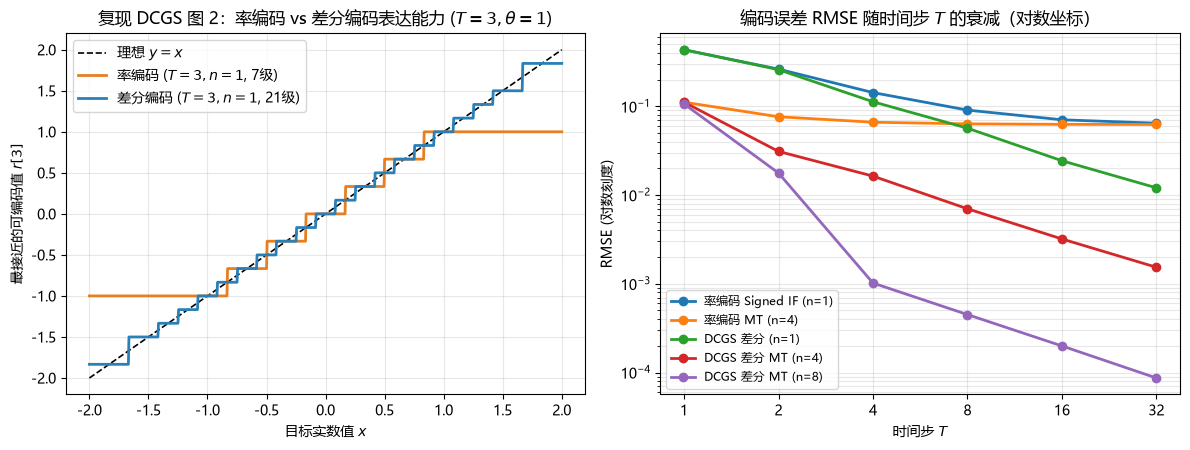

In [6]:
# 1) 精确枚举 T=3, theta=1, n=1 的可达编码集合 (复现 DCGS Fig. 2)
levels_n1 = [-1.0, 0.0, 1.0]
rate_vals = sorted(set((a + b + c) / 3.0 for a in levels_n1 for b in levels_n1 for c in levels_n1))
diff_vals = sorted(set(a + b / 2.0 + c / 3.0 for a in levels_n1 for b in levels_n1 for c in levels_n1))
print(f"T=3, n=1, theta=1 可达值个数: 率编码 = {len(rate_vals)} 个 (范围 [{min(rate_vals):.3f}, {max(rate_vals):.3f}]), "
      f"差分编码 = {len(diff_vals)} 个 (范围 [{min(diff_vals):.3f}, {max(diff_vals):.3f}])")
assert len(rate_vals) == 7
assert np.isclose(max(diff_vals), 11.0 / 6.0)

xs_plot = np.linspace(-2.0, 2.0, 801)
rate_arr = np.array(rate_vals)
diff_arr = np.array(diff_vals)
rate_fit = rate_arr[np.argmin(np.abs(xs_plot[:, None] - rate_arr[None, :]), axis=1)]
diff_fit = diff_arr[np.argmin(np.abs(xs_plot[:, None] - diff_arr[None, :]), axis=1)]

# 2) 500 个随机实数样本上的 RMSE & 脉冲率对比 (T = 1, 2, 4, 8, 16, 32)
rng = np.random.default_rng(2025)
samples = rng.normal(0.0, 0.5, size=500)
T_list = [1, 2, 4, 8, 16, 32]
configs = [
    ("率编码 Signed IF (n=1)", "rate", 1),
    ("率编码 MT (n=4)", "rate", 4),
    ("DCGS 差分 (n=1)", "diff", 1),
    ("DCGS 差分 MT (n=4)", "diff", 4),
    ("DCGS 差分 MT (n=8)", "diff", 8),
]

results_rmse = {name: [] for name, _, _ in configs}
results_spikes = {name: [] for name, _, _ in configs}

for name, mode, n_th in configs:
    for T in T_list:
        preds = []
        tot_spikes = 0
        for val in samples:
            if mode == "rate":
                rows = run_rate_mt(val, T=T, theta=1.0, n=n_th)
                preds.append(rows[-1][-1])
                tot_spikes += sum(1 for row in rows if abs(row[3]) > 1e-12)
            else:
                rows = run_diff_mt(val, T=T, theta=1.0, n=n_th)
                preds.append(rows[-1][-1])
                tot_spikes += sum(1 for row in rows if abs(row[5]) > 1e-12)
        rmse = float(np.sqrt(np.mean((np.array(preds) - samples) ** 2)))
        avg_sp = tot_spikes / len(samples)
        results_rmse[name].append(rmse)
        results_spikes[name].append(avg_sp)

print("\n=== 500 个随机实数 N(0, 0.5^2) 编码 RMSE 对照表 ===")
header = f"{'方法':<24} | " + " | ".join(f"T={T:<2d}" for T in T_list)
print(header)
print("-" * len(header))
for name, _, _ in configs:
    vals_str = " | ".join(f"{v:.4f}" for v in results_rmse[name])
    print(f"{name:<24} | {vals_str}")

print("\n=== 平均每神经元累计非零脉冲数 (越少越省电) ===")
print(header)
print("-" * len(header))
for name, _, _ in configs:
    vals_str = " | ".join(f"{v:6.2f}" for v in results_spikes[name])
    print(f"{name:<24} | {vals_str}")

# 确认 T=4 时 DCGS n=8 的 RMSE < 0.005 且显著优于率编码 n=1
assert results_rmse["DCGS 差分 MT (n=8)"][2] < 0.005
assert results_rmse["DCGS 差分 MT (n=8)"][2] < results_rmse["率编码 Signed IF (n=1)"][2] * 0.05

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(xs_plot, xs_plot, 'k--', lw=1.2, label='理想 $y=x$')
axes[0].plot(xs_plot, rate_fit, color='#e67e22', lw=2.0, label='率编码 ($T=3, n=1$, 7级)')
axes[0].plot(xs_plot, diff_fit, color='#2980b9', lw=2.0, label='差分编码 ($T=3, n=1$, 21级)')
axes[0].set_title(r'复现 DCGS 图 2：率编码 vs 差分编码表达能力 ($T=3, \theta=1$)')
axes[0].set_xlabel('目标实数值 $x$')
axes[0].set_ylabel('最接近的可编码值 $r[3]$')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

for name, _, _ in configs:
    axes[1].plot(T_list, results_rmse[name], marker='o', lw=2, label=name)
axes[1].set_yscale('log')
axes[1].set_xscale('log', base=2)
axes[1].set_xticks(T_list)
axes[1].set_xticklabels([str(t) for t in T_list])
axes[1].set_title('编码误差 RMSE 随时间步 $T$ 的衰减（对数坐标）')
axes[1].set_xlabel('时间步 $T$')
axes[1].set_ylabel('RMSE (对数刻度)')
axes[1].legend(fontsize=8.5)
axes[1].grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.show()
